# Audio classification

Một ứng dụng cần phân biệt hai tín hiệu: âm thấp rồi âm cao là “bắt đầu”, âm cao rồi âm thấp là “kết thúc”. Hai tín hiệu có cùng các tần số, chỉ khác thứ tự, nên một biểu diễn chỉ đếm tần số sẽ không phân biệt được. Bài này dùng ví dụ đó để chọn biểu diễn cho bài phân loại âm thanh, dựng baseline rồi CNN, xử lý các clip dài ngắn khác nhau, và dùng embedding từ model âm thanh pretrained.

> **Mục tiêu**
>
> - Chọn head, loss và metric cho từng loại bài phân loại âm thanh.
> - Dựng baseline và CNN trên log-mel.
> - Chia dữ liệu theo người nói hoặc phiên ghi.
> - Xử lý clip dài bằng cửa sổ; dùng embedding từ HuBERT, wav2vec2.

## Trước model: một clip có mấy nhãn?

Audio classification dự đoán nhãn từ một clip ($B$ là số clip trong batch, không phải số frame):

- **Một lớp trong $C$ lớp**: logits shape `(B,C)`, nhãn là số nguyên shape `(B,)`, dùng cross-entropy.
- **Nhiều nhãn** (multi-label), như clip vừa có tiếng xe vừa có tiếng nói: mỗi lớp một biến có/không, logits và nhãn shape `(B,C)`, dùng BCEWithLogitsLoss.

Softmax ép tổng xác suất bằng 1 không hợp cho những sự kiện có thể đồng thời xuất hiện.

Nếu đề hỏi “chuông xuất hiện lúc nào?”, một nhãn cho cả clip không đủ: cần event detection hoặc frame classification, logits shape `(B,T,C)` và cách chấm theo thời gian. Phần còn lại của bài làm bài toán **hai lớp loại trừ nhau** trên tín hiệu tổng hợp: đủ nhỏ để chạy CPU trong vài giây, và đáp án biết trước nên mọi con số đều giải thích được.



**Hỏi nhanh.** Mỗi clip 10 giây có thể chứa tiếng xe, tiếng nói, cả hai, hoặc không có gì. Đề chấm xác suất riêng cho từng loại. Nên dùng head và loss nào?

- A. Softmax hai lớp với CrossEntropyLoss, nhãn là âm to hơn
- B. Hai logits độc lập, sigmoid, với BCEWithLogitsLoss
- C. Softmax hai lớp, đặt ngưỡng 0.5 riêng trên mỗi cột
- D. Softmax ba lớp gồm xe, nói và cả hai, với CrossEntropyLoss

<details><summary>Đáp án</summary>

B. Hai logits độc lập, sigmoid, với BCEWithLogitsLoss

Đây là bài nhiều nhãn. Hai xác suất phải được phép cùng cao, khi clip có cả hai, hoặc cùng thấp, khi clip không có gì. Vì vậy mỗi loại là một câu hỏi có hay không riêng. Softmax ép hai cột cộng lại bằng 1. Clip có cả hai thì tốt nhất chỉ được 0.5 và 0.5, nên ngưỡng 0.5 trên từng cột gần như không bao giờ báo được cả hai. Clip trống thì vẫn phải chia 1 cho hai loại. Lấy âm to hơn làm nhãn là vứt bỏ loại còn lại. Softmax ba lớp thiếu trường hợp “không có gì”, và không cho xác suất riêng của từng loại như đề chấm.

</details>

## Bộ dữ liệu nhỏ có đáp án kiểm được

Ta tạo 20 phiên giả lập. Mỗi phiên có một độ lệch cao độ (một trong bốn mức); trong mỗi phiên sinh hai cặp clip với pha, biên độ và nhiễu khác nhau. Nhãn 1 là thấp→cao, nhãn 0 là cao→thấp. Hai clip trong một cặp dùng đúng hai nửa waveform giống nhau, chỉ đổi thứ tự.

Phiên đóng vai một buổi thu thật: các clip của nó có chung dấu vết (ở đây là độ lệch cao độ), nên khi chia dữ liệu phải giữ trọn phiên ở một phía.

Mỗi clip có 1024 mẫu ở 2048 Hz, dài 0.5 giây. Ta dùng window 128 mẫu, hop 128, không chồng lấp, không padding: 8 frame. Cả hai nửa dài 512 mẫu nên ranh giới nằm đúng giữa frame 4 và 5. Chủ ý này giúp thí nghiệm pooling sạch: mỗi cặp chỉ hoán vị bốn frame đầu với bốn frame cuối.

In [ ]:
import numpy as np
from scipy.signal.windows import hann

rng = np.random.default_rng(72)
sample_rate = 2048
window_size = 128
frequencies = np.fft.rfftfreq(window_size, d=1 / sample_rate)
max_mel = 2595 * np.log10(1 + frequencies[-1] / 700)
mel_edges = np.linspace(0, max_mel, 26)  # 24 band cần 26 mép
hz_edges = 700 * (10 ** (mel_edges / 2595) - 1)
filters = []
for left, middle, right in zip(hz_edges, hz_edges[1:], hz_edges[2:]):
    rising = (frequencies - left) / (middle - left)
    falling = (right - frequencies) / (right - middle)
    filters.append(np.maximum(0, np.minimum(rising, falling)))
filters = np.array(filters)

def make_log_mel(signal):
    frames = signal.reshape(8, window_size)
    spectrum = np.fft.rfft(frames * hann(window_size, sym=False), axis=1)
    power = (np.abs(spectrum) / (window_size / 2)) ** 2
    return 10 * np.log10(np.maximum(filters @ power.T, 1e-8))

features, labels, groups = [], [], []
half_time = np.arange(512) / sample_rate
for session in range(20):
    frequency_offset = 16 * (session % 4)
    for repetition in range(2):
        phase = rng.uniform(0, 2 * np.pi)
        amplitude = rng.uniform(0.5, 0.9)
        low = amplitude * np.sin(2 * np.pi * (208 + frequency_offset) * half_time + phase)
        high = amplitude * np.sin(2 * np.pi * (608 + frequency_offset) * half_time + phase)
        low += rng.normal(0, 0.035, 512)
        high += rng.normal(0, 0.035, 512)
        for label, halves in [(1, [low, high]), (0, [high, low])]:
            features.append(make_log_mel(np.concatenate(halves)))
            labels.append(label)
            groups.append(session)
features = np.array(features, dtype=np.float32)
labels = np.array(labels)
groups = np.array(groups)
print(features.shape, labels.shape)
print(f"thời lượng = {1024 / sample_rate:.2f} s")

(80, 24, 8) (80,)
thời lượng = 0.50 s


Ta có `(80,24,8)`: 80 clip, 24 mel band, 8 frame. Đây là log power với mốc cố định 1, khác bài 7.1 dùng đỉnh của từng clip. Mốc cố định giữ mọi clip trên cùng thang số, nên clip to và clip nhỏ không bị kéo về cùng mức trước bước chuẩn hóa. Khi dùng model pretrained, sample rate, số band, window và hop lấy theo processor của checkpoint, không tự chọn như ở đây.



**Hỏi nhanh.** Mỗi cặp clip dùng đúng hai nửa waveform giống nhau, chỉ đổi thứ tự. Thiết kế này nhằm mục đích gì?

- A. Để mỗi phiên có bản sao của cùng clip ở cả train và validation
- B. Để hai lớp khác nhau rõ ở cao độ trung bình của cả clip
- C. Để mọi đặc trưng bỏ qua thứ tự đều trùng nhau trong một cặp
- D. Để năng lượng hai nửa khác nhau, dễ thấy trên log-mel

<details><summary>Đáp án</summary>

C. Để mọi đặc trưng bỏ qua thứ tự đều trùng nhau trong một cặp

Hai clip một cặp có cùng tập frame, nên trung bình, tổng năng lượng, max hay phổ trung bình đều bằng nhau. Chỉ còn thứ tự là phân biệt được nhãn. Nhờ vậy, chênh lệch giữa baseline và CNN ở các mục sau chỉ có thể đến từ thông tin thứ tự, tức đây là một thí nghiệm có kiểm soát.

Cả cặp thuộc cùng phiên, nên luôn nằm cùng một phía khi chia, và không có bản sao nào vượt qua split. Cao độ trung bình của hai lớp như nhau, vì dùng cùng hai nửa. Hai nửa lại có cùng biên độ, nên năng lượng cũng như nhau.

</details>

## Validation: tách phiên trước, không tách crop sau

Ngoài âm cần phân loại, bản ghi còn chứa giọng người, microphone, căn phòng và âm nền. Nếu cùng một người hoặc cùng một buổi thu nằm ở cả train lẫn validation, model có thể dựa vào những dấu vết ấy và validation sẽ lạc quan. Group chọn theo điều đề muốn tổng quát hóa: test là người nói mới thì group theo speaker ID; test là buổi thu mới của những người đã có trong train thì group theo phiên là đủ.

Ta dùng `GroupShuffleSplit`, giữ trọn từng phiên ở một phía. `test_size=0.25` ở splitter này là **tỉ lệ group**, chưa chắc là tỉ lệ clip; trong dữ liệu của bài, mỗi group có đúng bốn clip nên hai tỉ lệ bằng nhau.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=7)
train_indices, valid_indices = next(splitter.split(features, labels, groups))
train_groups = set(groups[train_indices])
valid_groups = set(groups[valid_indices])
print(len(train_indices), len(valid_indices))
print(f"group giao nhau = {len(train_groups & valid_groups)}")
print(np.bincount(labels[valid_indices]))

60 20
group giao nhau = 0
[10 10]


Ta cần nhìn giao group bằng 0 và số mẫu mỗi lớp. Group split không tự bảo đảm mọi lớp xuất hiện; khi dữ liệu thật có người chỉ nói một từ, phải kiểm phân bố nhãn và có thể chọn GroupKFold hoặc StratifiedGroupKFold. Mọi crop và augmentation chỉ được tạo sau phép chia này.



**Hỏi nhanh.** Đề chấm trên những người nói chưa từng xuất hiện. Dữ liệu có 30 người, mỗi người thu 3 phiên. Một đội chia GroupKFold theo mã phiên. Rủi ro chính là gì?

- A. Một người có phiên ở cả hai phía, nên validation lạc quan
- B. Không có rủi ro, vì không phiên nào bị chia ra hai phía
- C. GroupKFold báo lỗi, vì số phiên không chia hết cho số fold
- D. Validation bi quan hơn test, vì mỗi phiên có quá ít clip để học

<details><summary>Đáp án</summary>

A. Một người có phiên ở cả hai phía, nên validation lạc quan

Group theo phiên chỉ ngăn một phiên bị chia đôi. Ba phiên của cùng một người vẫn có thể rơi vào cả train lẫn validation. Model nhận ra giọng quen, nên validation đo “phiên mới của người cũ”, chứ không phải “người mới” như test. Group phải theo speaker ID. GroupKFold không đòi số group chia hết cho số fold, chỉ cần số group không ít hơn số fold. Số clip mỗi phiên không làm validation bi quan ở đây. Sai lệch đến từ giọng quen, nên theo chiều lạc quan.

</details>

## Baseline: trung bình từng mel band

Một baseline nhanh là gộp thời gian: mỗi band lấy trung bình log power, cho vector 24 số. Logistic regression học từ vector ấy, với StandardScaler chỉ fit trên train. Baseline không cần GPU, thuận tiện để kiểm pipeline và có mốc chấm. Có thể dự đoán trước rằng hai clip chỉ đổi thứ tự frame có cùng trung bình, nên vector này không biết thấp→cao hay cao→thấp.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

pooled_features = features.mean(axis=2)
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=300))
baseline.fit(pooled_features[train_indices], labels[train_indices])
baseline_predictions = baseline.predict(pooled_features[valid_indices])
print(f"accuracy = {accuracy_score(labels[valid_indices], baseline_predictions):.3f}")
print(f"macro-F1 = {f1_score(labels[valid_indices], baseline_predictions, average='macro'):.3f}")
print(confusion_matrix(labels[valid_indices], baseline_predictions))

accuracy = 0.500
macro-F1 = 0.333
[[10  0]
 [10  0]]


Confusion matrix có hàng là nhãn thật, cột là nhãn dự đoán, theo thứ tự 0 rồi 1: cả 20 clip validation đều bị đoán là lớp 0. Accuracy 0.500 đúng bằng mốc đoán một lớp, và đây là hệ quả của biểu diễn, không phải lỗi optimizer.

Macro-F1 lấy trung bình F1 của từng lớp, không trọng số theo số mẫu: lớp bị bỏ quên có F1 bằng 0 và kéo cả trung bình xuống. Trên tập lệch lớp, đó là lỗi mà accuracy che mất.

**Hỏi nhanh.** Baseline đoán lớp 0 cho cả 20 clip validation, mỗi lớp 10 clip. Accuracy là 0.500, macro-F1 là 0.333. F1 của lớp 0 và của lớp 1 lần lượt là bao nhiêu?

- A. 0.500 và 0.167
- B. 0.667 và 0
- C. 1.000 và 0
- D. 0.333 và 0.333

<details><summary>Đáp án</summary>

B. 0.667 và 0

Lớp 0 có precision $10/20 = 0.5$ và recall $10/10 = 1$, nên F1 bằng $2\cdot 0.5\cdot 1/1.5 \approx 0.667$. Lớp 1 không có dự đoán đúng nào, nên F1 bằng 0. Trung bình hai lớp là 0.333. 1.000 là nhầm recall với F1. 0.333 cho cả hai lớp là coi lỗi chia đều, trong khi lỗi dồn hết vào lớp 1. Cặp 0.500 và 0.167 cũng cho trung bình 0.333, nhưng không ứng với confusion matrix này.

</details>

Ví dụ tính tay: hai band trên hai frame của clip A là $\begin{bmatrix}3&0\\0&3\end{bmatrix}$, clip B là $\begin{bmatrix}0&3\\3&0\end{bmatrix}$. Cả hai đều có vector trung bình $(1.5,1.5)$. Mọi hàm chỉ nhận vector ấy cho cùng kết quả trên hai clip, dù nhãn khác nhau. Trong dữ liệu của bài, hai clip một cặp luôn nằm cùng phía, nên mỗi cặp luôn có một clip đúng và một clip sai: accuracy 0.500 là chắc chắn, model nào cũng vậy.

Muốn giải bài phải thay biểu diễn hoặc cho model giữ thứ tự. Một cách thay biểu diễn rẻ là thêm trung bình **delta**, hiệu giữa hai frame kề nhau. Tổng các hiệu bằng frame cuối trừ frame đầu, nên trung bình delta trên 8 frame bằng $(\text{cuối}-\text{đầu})/7$. Với hai clip trên, delta của A là $(-3,3)$, của B là $(3,-3)$: đổi dấu khi đảo thứ tự.



**Hỏi nhanh.** Thay mean bằng ba thống kê theo thời gian của mỗi band là mean, std và max, được 72 số. Logistic regression trên vector này có tách được hai lớp của bài không?

- A. Có, vì max cho biết frame nào có năng lượng lớn nhất
- B. Có, vì std đo mức thay đổi của band theo thời gian
- C. Không, trừ khi tăng `max_iter` để solver hội tụ hẳn
- D. Không, vì cả ba đều giữ nguyên khi đổi thứ tự frame

<details><summary>Đáp án</summary>

D. Không, vì cả ba đều giữ nguyên khi đổi thứ tự frame

Max cho giá trị lớn nhất, nhưng không cho vị trí của nó. Std đo độ phân tán, không đo hướng thay đổi. Cả ba đều là hàm của tập frame, nên hai clip một cặp vẫn có cùng một vector, và accuracy vẫn đúng 0.500, dù solver hội tụ tới đâu. Trung bình delta thì khác, vì nó đổi dấu khi đảo thứ tự.

</details>

## CNN trên log-mel: giữ hai trục cho đến head

Log-mel là ma trận nhưng không phải ảnh tự nhiên: trục ngang là thời gian, trục dọc là tần số, và dịch lên một band là đổi cao độ chứ không giống dịch một vật trong ảnh. CNN nhỏ vẫn nhận nó như một ảnh một kênh, học các mẫu cục bộ trên hai trục.

Ta thêm chiều channel: `(B,1,24,8)`. Kernel $3\times3$ với padding 1 giữ chiều cao và chiều rộng; 4 output channel cho `(B,4,24,8)`. Flatten thành 768 số rồi head trả 2 logits. Flatten giữ vị trí từng ô, nên head biết âm nào ở nửa đầu, âm nào ở nửa sau.

Mean/std dưới đây tính theo train, riêng cho mỗi mel band, gộp các clip và frame. `keepdims=True` cho shape `(1,24,1)`, broadcasting đúng lên `(80,24,8)`. Validation dùng lại đúng thống kê ấy. CNN khởi tạo ngẫu nhiên và học từ đầu trên 60 clip train: cả tập trong một batch, 30 bước Adam.

In [ ]:
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(7)
band_mean = features[train_indices].mean(axis=(0, 2), keepdims=True)
band_std = features[train_indices].std(axis=(0, 2), keepdims=True)
standardized = (features - band_mean) / np.maximum(band_std, 1e-6)
inputs = torch.tensor(standardized[:, None], dtype=torch.float32)
targets = torch.tensor(labels, dtype=torch.long)
model = nn.Sequential(
    nn.Conv2d(1, 4, 3, padding=1),
    nn.ReLU(),
    nn.Flatten(),
    nn.Linear(4 * 24 * 8, 2),
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()
model.train()
for epoch in range(30):
    optimizer.zero_grad()
    logits = model(inputs[train_indices])
    loss = criterion(logits, targets[train_indices])
    loss.backward()
    optimizer.step()
model.eval()
with torch.no_grad():
    predictions = model(inputs[valid_indices]).argmax(dim=1).numpy()
print(tuple(inputs.shape))
print(f"accuracy = {accuracy_score(labels[valid_indices], predictions):.3f}")
print(f"macro-F1 = {f1_score(labels[valid_indices], predictions, average='macro'):.3f}")
print(confusion_matrix(labels[valid_indices], predictions))

(80, 1, 24, 8)
accuracy = 1.000
macro-F1 = 1.000
[[10  0]
 [ 0 10]]




Trên cùng 20 clip validation, CNN đúng cả 20, baseline chỉ đúng 10. Hai model thấy cùng dữ liệu; khác biệt duy nhất là thông tin vị trí còn đến được head. Kết quả chỉ xác nhận điều đã cài vào quy tắc sinh dữ liệu: ở đây thứ tự quyết định nhãn. Với âm thật nhiều microphone, tiếng nền hoặc sự kiện chồng lấp, chọn CNN hay embedding phải đo trên validation của chính đề.

Mean pooling không có lỗi tự thân; vấn đề là gộp **trước khi** có gì đọc được thứ tự. Đặt mean theo thời gian sau lớp conv và so hai kernel: $3\times3$ phủ ba frame kề nhau, $(3,1)$ chỉ phủ ba band trong một frame.

In [ ]:
class TimeMean(nn.Module):
    def forward(self, x):  # (B,C,band,frame) -> (B,C,band)
        return x.mean(dim=3)

def train_time_mean(kernel_size, padding):
    torch.manual_seed(7)
    head = nn.Sequential(
        nn.Conv2d(1, 4, kernel_size, padding=padding),
        nn.ReLU(),
        TimeMean(),
        nn.Flatten(),
        nn.Linear(4 * 24, 2),
    )
    optimizer = torch.optim.Adam(head.parameters(), lr=0.01)
    for epoch in range(30):
        optimizer.zero_grad()
        criterion(head(inputs[train_indices]), targets[train_indices]).backward()
        optimizer.step()
    head.eval()
    with torch.no_grad():
        scores = [accuracy_score(labels[part], head(inputs[part]).argmax(dim=1).numpy())
                  for part in (train_indices, valid_indices)]
    return f"train {scores[0]:.3f}, valid {scores[1]:.3f}"

print("3x3 rồi mean thời gian:", train_time_mean(3, 1))
print("3x1 rồi mean thời gian:", train_time_mean((3, 1), (1, 0)))

3x3 rồi mean thời gian: train 1.000, valid 0.950
3x1 rồi mean thời gian: train 0.500, valid 0.500


Kernel $3\times3$ đặt trên frame 4 và 5 nhìn thấy chỗ chuyển: thấp ở trái, cao ở phải chỉ có trong clip nhãn 1. ReLU giữ phản ứng ấy, mean theo thời gian cộng nó vào vector, nên head vẫn đọc được thứ tự: đúng hết train, sai 1 trong 20 clip validation sau 30 bước. Kernel $(3,1)$ xử lý từng frame riêng, nên sau mean hai clip một cặp lại có cùng vector, như baseline: đúng 0.500 ngay cả trên train, và không cách train nào vượt được mốc ấy.

Đây cũng là lý do mean pooling trên hidden state của encoder pretrained (mục sau) thường dùng được: mỗi vector đã trộn ngữ cảnh trước khi bị gộp.

Khi train thật với thư viện, Dataset trả tensor có tiền xử lý nhất quán, DataLoader gom batch, `model.train()` bật hành vi huấn luyện, `model.eval()` cùng `no_grad()` dùng cho validation. Lưu checkpoint tốt nhất theo metric đề chấm, kèm thống kê chuẩn hóa; điểm của epoch cuối không thay được việc chọn checkpoint theo validation.

**Hỏi nhanh.** Đổi kernel thành $(1, 3)$, tức mỗi lần chỉ nhìn một band nhưng nhìn ba frame kề nhau, với padding `(0, 1)`, vẫn ReLU rồi mean theo thời gian. Model có học được không?

- A. Học được, vì kernel thấy band bật hay tắt ở chỗ chuyển
- B. Không, vì mean theo thời gian luôn xóa hết thứ tự frame
- C. Không, vì kernel phải phủ cả hai trục mới thấy được thứ tự
- D. Học được, nhưng chỉ khi bỏ ReLU đứng trước bước mean

<details><summary>Đáp án</summary>

A. Học được, vì kernel thấy band bật hay tắt ở chỗ chuyển

Ở chỗ chuyển từ frame 4 sang frame 5, band của âm thấp đi từ có năng lượng sang gần như không với nhãn 1, hoặc ngược lại với nhãn 0. Kernel rộng ba frame trên một band phân biệt được “tắt” với “bật”. Mean chỉ cộng các phản ứng đã mang thứ tự. Điều kiện là receptive field theo thời gian phải vượt qua ranh giới, không cần phủ trục tần số. ReLU không phải thứ xóa thứ tự. Kernel $(3, 1)$ mất thứ tự vì không nhìn qua hai frame, có ReLU hay không cũng vậy.

</details>



## Clip dài ngắn khác nhau: cắt cửa sổ, gộp dự đoán

Head Flatten của bài cần đúng 8 frame, trong khi clip thật dài ngắn khác nhau. Cách làm phổ biến: khi train, cắt ngẫu nhiên một cửa sổ độ dài cố định từ mỗi clip đã nằm ở train, clip ngắn hơn thì pad và giữ mask. Mỗi epoch thấy một đoạn khác, nên cửa sổ ngẫu nhiên cũng là augmentation.

Cái giá nằm ở nhãn: đề thường gán nhãn cho cả clip (weak label), và một cửa sổ có thể không chứa bằng chứng nào. Clip 10 giây nhãn “có chó sủa” mà tiếng sủa chỉ dài 1 giây thì phần lớn cửa sổ 2 giây không nghe thấy tiếng sủa, nhưng vẫn mang nhãn dương.

Khi dự đoán, cắt clip thành các cửa sổ trượt cùng độ dài với lúc train, hop thường bằng nửa cửa sổ, chạy model trên từng cửa sổ rồi gộp về một dự đoán cho clip. Cách gộp đi theo câu hỏi của đề:

- **Trung bình xác suất** (hoặc logits) khi nhãn mô tả cả clip, như thể loại nhạc hay giọng người: mọi cửa sổ đều là bằng chứng, và cửa sổ chắc chắn nặng ký hơn cửa sổ phân vân.
- **Max** khi nhãn là “sự kiện xuất hiện ít nhất một lần”: một cửa sổ chắc chắn là đủ, các cửa sổ còn lại không được kéo điểm xuống.
- **Bỏ phiếu** theo argmax từng cửa sổ: đơn giản, nhưng bỏ mất độ chắc chắn.

Ví dụ tính tay: năm cửa sổ của một clip có xác suất “có còi” lần lượt 0.05, 0.10, 0.92, 0.08, 0.06. Trung bình bằng $1.21/5=0.242$, dưới ngưỡng 0.5 nên bỏ sót tiếng còi; max bằng 0.92.

Ngược lại, với nhãn thể loại nhạc, max để một cửa sổ lạ (tiếng vỗ tay, một đoạn im) quyết định cả clip. Độ dài cửa sổ, hop và cách gộp là siêu tham số: chọn bằng metric trên validation ở mức clip, đúng đơn vị đề chấm, không phải accuracy từng cửa sổ.



**Hỏi nhanh.** Ba cửa sổ của một clip cho xác suất lớp A và lớp B là $(0.9, 0.1)$, $(0.4, 0.6)$ và $(0.45, 0.55)$. Bỏ phiếu theo argmax và lấy trung bình xác suất lần lượt chọn lớp nào?

- A. Bỏ phiếu chọn A, trung bình chọn A
- B. Bỏ phiếu chọn A, trung bình chọn B
- C. Bỏ phiếu chọn B, trung bình chọn A
- D. Bỏ phiếu chọn B, trung bình chọn B

<details><summary>Đáp án</summary>

C. Bỏ phiếu chọn B, trung bình chọn A

B thắng hai trong ba cửa sổ, nhưng đều sát nút. Trung bình xác suất của A là $(0.9 + 0.4 + 0.45)/3 \approx 0.583$, vì một cửa sổ rất chắc chắn nặng hơn hai cửa sổ còn phân vân. Bỏ phiếu thì bỏ mất độ chắc chắn ấy. Cách nào hợp với đề hơn là câu hỏi cho validation ở mức clip. Điều cần nhớ là hai cách có thể cho hai đáp án khác nhau trên cùng một clip.

</details>

## Embedding HuBERT, wav2vec2 và pooling có mask

Một hướng khác là dùng audio encoder đã học trên hàng trăm giờ tiếng nói trở lên, lấy hidden states `(B,T',D)`, rồi huấn luyện bộ phân loại nhỏ. $T'$ là số bước **sau encoder**: chuỗi conv đầu của wav2vec2 và HuBERT gộp khoảng 320 mẫu ở 16 kHz thành một bước, tức 49 bước cho một giây; $D$ là chiều embedding (768 với bản base).

[wav2vec 2.0](https://arxiv.org/abs/2006.11477) học biểu diễn bằng masking và bài toán tương phản; [HuBERT](https://arxiv.org/abs/2106.07447) dự đoán nhãn cụm ẩn của các đoạn bị che. Hai họ checkpoint này học trên tiếng nói, nên mạnh nhất với nhiệm vụ về giọng và lời; với âm môi trường hay nhạc, lợi ích phải đo trên validation.

Mean pooling ở đây khác mean log-mel thô: như CNN $3\times3$ ở trên, mỗi hidden state đã trộn ngữ cảnh nhờ encoder trước khi bị gộp. Dù vậy pooling vẫn là lựa chọn cần chấm: mean/std pooling, attention pooling, hoặc một head chuỗi nếu nhãn cần thứ tự. Clip có độ dài khác nhau phải tránh lấy trung bình cả phần padding:

$$\mathbf{z}_i=\frac{\sum_t a_{i,t}\mathbf{h}_{i,t}}{\sum_t a_{i,t}},$$

$a_{i,t}$ bằng 1 ở bước thật, bằng 0 ở padding; mẫu số là số bước thật, không phải độ dài đã pad. Ta kiểm cơ chế trên hai chuỗi hidden nhỏ đặt bằng tay, cùng dạng `(B,T',D)` với output của encoder:

In [ ]:
hidden = np.array([
    [[1, 2], [3, 4], [0, 0], [0, 0]],
    [[2, 0], [4, 2], [6, 4], [8, 6]],
], dtype=float)
frame_mask = np.array([[1, 1, 0, 0], [1, 1, 1, 1]])
masked_mean = (hidden * frame_mask[..., None]).sum(axis=1)
masked_mean /= frame_mask.sum(axis=1, keepdims=True)
print(hidden.mean(axis=1))
print(masked_mean)

[[1.  1.5]
 [5.  3. ]]
[[2. 3.]
 [5. 3.]]


Clip đầu có hai vector thật; $(1+3,2+4)/2=(2,3)$. Chia cho 4 thay vì 2 làm nó thành $(1,1.5)$: embedding phụ thuộc lượng padding, tức phụ thuộc clip nào được ghép cùng batch. Clip thứ hai không có padding nên hai cách bằng nhau.

Mask waveform dài $N$ không nhân trực tiếp được với hidden state dài $T'$: phải đổi độ dài từng clip qua các lớp convolution của encoder, mỗi lớp kernel $k$, stride $s$ cho $\lfloor (L-k)/s\rfloor+1$ bước, rồi tạo frame mask.



[Script của chương](recipes/README.md) đi đúng quy trình này với checkpoint và file WAV có sẵn trên máy. Nó nhận một bảng gồm đường dẫn, nhãn, group và split, rồi chạy hai bước:

1. `--check` kiểm file WAV và sample rate, processor, loại model, tệp trọng số, ID không trùng và không group nào nằm ở cả hai phía, mà chưa nạp model.
2. `--run` nạp checkpoint bằng `from_pretrained(..., local_files_only=True)`, trích embedding từng clip, mean-pool với frame mask tính từ kernel và stride, rồi fit StandardScaler nối LogisticRegression trên train.

Kết quả là accuracy, macro-F1 và confusion matrix trên validation, cùng tệp lưu vector để thử head khác mà không chạy lại encoder. Đặt các số ấy cạnh baseline log-mel trên **cùng** split mới biết embedding giúp bao nhiêu. `Model(config)` chỉ dựng kiến trúc với trọng số ngẫu nhiên, nên script dừng khi checkpoint thiếu trọng số thay vì âm thầm khởi tạo mới.

**Hỏi nhanh.** Một clip 0.5 giây cho embedding khác nhau khi được ghép batch với một clip 0.5 giây khác và khi được ghép với một clip 2 giây. Chạy lại cùng một batch thì ra đúng kết quả cũ. Nguyên nhân có khả năng nhất là gì?

- A. Dropout của encoder vẫn bật, nên output đổi ngẫu nhiên
- B. Processor resample clip ngắn theo clip dài nhất trong batch
- C. StandardScaler của head được fit lại cho từng batch mới
- D. Pooling chia cho mọi bước hidden, gồm cả các bước padding

<details><summary>Đáp án</summary>

D. Pooling chia cho mọi bước hidden, gồm cả các bước padding

Ghép với clip 2 giây thì clip ngắn bị pad thêm 1.5 giây. Nếu pooling chia cho mọi bước, hoặc encoder không nhận attention mask khi checkpoint cần, vector sẽ phụ thuộc lượng padding, tức phụ thuộc clip được ghép cùng batch. Dropout thì làm kết quả đổi cả khi chạy lại cùng batch, trái với mô tả. Processor pad chứ không resample theo độ dài. Scaler được fit trên train một lần, không đổi theo batch. Sửa bằng mask theo số bước thật, hoặc trích từng clip một như script của chương.

</details>

## Augmentation cho âm thanh

Augmentation phải giữ đáp án:

- Phát ngược (time reversal) không hợp với hai nhãn của bài: nó đổi “bắt đầu” thành “kết thúc”.
- Đổi cao độ (pitch shift) cần kiểm xem cao độ tuyệt đối có phải nhãn hay không.
- SpecAugment (bài 7.1) chỉ dùng trên train; độ rộng time mask phải nhỏ hơn sự kiện ngắn nhất mang nhãn, nếu không một mẫu “có sự kiện” có thể bị che mất đúng sự kiện mà vẫn giữ nhãn dương.

Lớp hiếm cần được theo dõi riêng: recall từng lớp và macro-F1 cho biết model có bỏ quên lớp ấy không; class weight trong loss hoặc lấy mẫu lại **trong train** là hai cách sửa đầu tiên.

**Hỏi nhanh.** Đề phân loại tiếng gõ cửa, tiếng ho và tiếng còi, với hop 10 ms. Tiếng gõ ngắn nhất chỉ dài khoảng 5 frame. Một đội bật time masking, che ngẫu nhiên tới 40 frame liên tiếp, và giữ nhãn cũ. Rủi ro chính là gì?

- A. Mask che trọn tiếng gõ, sinh ra mẫu “gõ cửa” không còn tiếng gõ
- B. Không có rủi ro, vì masking chỉ che chứ không dịch chuyển gì
- C. Masking đảo thứ tự các frame, giống hệt time reversal
- D. Model sẽ chỉ còn học tiếng còi, vì còi là âm dài nhất

<details><summary>Đáp án</summary>

A. Mask che trọn tiếng gõ, sinh ra mẫu “gõ cửa” không còn tiếng gõ

40 frame là 0.4 giây, gấp tám lần tiếng gõ ngắn nhất. Có những lần mask phủ kín cả sự kiện, và mẫu còn lại không chứa bằng chứng gì mà vẫn mang nhãn “gõ cửa”, tức nhãn bị nhiễu. Đúng là masking không dịch chuyển hay đảo frame, nhưng giữ thứ tự chưa đủ để giữ nhãn. Tiếng còi dài vẫn còn phần lớn sau khi bị che, nên lớp âm dài chịu thiệt ít hơn, chứ model không chỉ học mỗi còi. Hãy chọn độ rộng mask nhỏ hơn sự kiện ngắn nhất, và nghe lại vài mẫu sau augmentation.

</details>



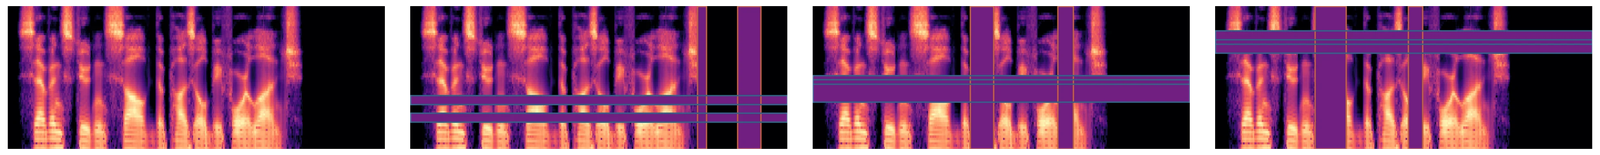

## Khi đi thi

- **Baseline trước, model sau.** Đặc trưng gộp với logistic regression chạy trong vài giây: dùng nó kiểm file, ID, class mapping và metric trước khi tốn GPU cho CNN hay encoder.
- **Split theo đơn vị của test.** Đọc đề xem test là người nói mới, thiết bị mới hay buổi thu mới, rồi chọn group tương ứng; giữ một split cố định cho mọi thí nghiệm.
- **Chấm ở mức clip, đúng metric.** Nếu cắt cửa sổ, gộp dự đoán về một dòng mỗi clip rồi mới tính macro-F1; theo dõi recall của lớp hiếm.
- **Trích embedding một lần, cache lại.** Lưu vector kèm ID, checkpoint và cấu hình processor; mỗi head mới không phải chạy encoder lại. Đo thời gian trích trên thiết bị được cấp trước khi chọn checkpoint lớn.
- **Kiểm file nộp.** Cột xác suất thứ $k$ phải ứng với đúng nhãn đề yêu cầu, và nhãn nộp phải nằm trong tập nhãn của đề. Đề chấm xác suất thì không nộp argmax. Chạy lại pipeline ở tiến trình mới trước khi nộp.

## Tóm tắt

- Chọn mức clip hay frame, single-label hay multi-label trước khi chọn head, loss, metric.
- Gộp theo thời gian trước khi có gì đọc thứ tự sẽ xóa thứ tự. CNN giữ vị trí đến head, hoặc gộp sau một lớp nhìn qua nhiều frame, thì giữ được.
- Split theo đơn vị cần tổng quát hóa, fit mọi thống kê trên train; macro-F1 và confusion matrix cho biết model sai lớp nào.
- Clip dài: cắt cửa sổ khi train, gộp xác suất (mean hoặc max tùy câu hỏi) khi dự đoán, chấm ở mức clip.
- Embedding pretrained cần checkpoint thật, processor đúng và pooling có mask theo độ dài sau encoder; so với baseline trên cùng validation.

## Kiểm tra cuối bài

**Câu 1.** Cùng một batch 12 clip, 5 lớp, logits `(12, 5)`. Ở bản A, mỗi clip thuộc đúng một lớp, dùng CrossEntropyLoss với nhãn là chỉ số lớp. Ở bản B, mỗi clip có nhiều nhãn, dùng BCEWithLogitsLoss. Target của A và B có shape và kiểu gì?

- A. A là `(12,)` kiểu integer, B là `(12, 5)` kiểu float
- B. A là `(12,)` kiểu integer, B là `(12, 5)` kiểu integer
- C. A là `(12, 1)` kiểu integer, B là `(12, 5)` kiểu float
- D. A là `(12, 5)` kiểu integer, B là `(12,)` kiểu float

<details><summary>Đáp án</summary>

A. A là `(12,)` kiểu integer, B là `(12, 5)` kiểu float

CrossEntropyLoss với nhãn chỉ số cần một số nguyên cho mỗi clip, nên shape là `(12,)`. BCEWithLogitsLoss cần target cùng shape với logits và kiểu float, vì mỗi ô là một xác suất có hay không. Target integer cho BCEWithLogitsLoss sẽ báo lỗi kiểu, “result type Float can't be cast to the desired output type Long”. Target `(12, 1)` cho CrossEntropyLoss sẽ báo lỗi “multi-target not supported”. Đổi chỗ hai shape là nhầm vai của hai loss.

</details>

**Câu 2.** Clip dài từ 2 đến 10 giây, mỗi giây có 100 frame log-mel. CNN của bài dùng Flatten rồi Linear cho đúng 8 frame. Xử lý độ dài thay đổi thế nào mà không vứt bỏ phần lớn clip dài?

- A. Cắt mọi clip về 2 giây đầu để Flatten có độ dài cố định
- B. Resample từng clip để mọi clip có cùng số mẫu waveform
- C. Dùng conv hoặc RNN theo thời gian, rồi gộp có mask trên các bước thật
- D. Giữ Flatten, vì Linear tự co giãn theo số frame của từng clip

<details><summary>Đáp án</summary>

C. Dùng conv hoặc RNN theo thời gian, rồi gộp có mask trên các bước thật

Mô hình đọc theo thời gian, như conv, RNN hay Transformer, chạy được trên chuỗi dài bất kỳ. Gộp có mask ở cuối cho một vector mỗi clip, không tính phần pad. Cắt cửa sổ rồi gộp dự đoán như mục trên cũng là một lời giải. Giữ 2 giây đầu là vứt tới 80% của clip 10 giây. Resample về cùng số mẫu rồi đọc ở sample rate cũ là kéo giãn thời gian và đổi cao độ, làm hỏng chính đặc trưng cần đọc. Linear có số đầu vào cố định, nên số phần tử sau Flatten khác đi là báo lỗi shape.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.6](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=8)

</details>

**Câu 3.** Có 8 phiên thu. Validation lấy 2 phiên bằng GroupShuffleSplit với `test_size=0.25`, và hai phiên đó chứa 40 trong 100 clip. Validation chiếm bao nhiêu phần trăm số group, và bao nhiêu phần trăm số clip?

- A. 25% số group, 25% số clip
- B. 40% số group, 25% số clip
- C. 40% số group, 40% số clip
- D. 25% số group, 40% số clip

<details><summary>Đáp án</summary>

D. 25% số group, 40% số clip

`test_size` của GroupShuffleSplit tính theo group, nên được $2/8 = 25\%$. Tỉ lệ clip là $40/100 = 40\%$, vì hai phiên này đông hơn trung bình. Hai tỉ lệ chỉ bằng nhau khi các group cùng cỡ, như dữ liệu của bài. Với các phiên dài ngắn khác nhau, hãy in số clip mỗi phía ra thay vì tin vào `test_size`.

</details>

**Câu 4.** Validation có 90 clip lớp A và 10 clip lớp B, là tiếng kính vỡ. Đề chấm macro-F1. Model P đoán toàn A. Model Q tìm được 8 clip B, nhưng gán nhầm 12 clip A thành B. Macro-F1 của P và của Q là bao nhiêu?

- A. P được 0.474, Q được 0.725
- B. P được 0.474, Q được 0.533
- C. P được 0.947, Q được 0.725
- D. P được 0.900, Q được 0.860

<details><summary>Đáp án</summary>

A. P được 0.474, Q được 0.725

Với P, F1 lớp A là $2\cdot 0.9\cdot 1/1.9 \approx 0.947$, lớp B bằng 0, trung bình là 0.474. Với Q, lớp B có precision $8/20$ và recall $8/10$, nên F1 bằng $16/30 \approx 0.533$. Lớp A đúng 78 clip, precision $78/80$, recall $78/90$, nên F1 bằng $156/170 \approx 0.918$. Trung bình là 0.725. Accuracy của P và Q là 0.90 và 0.86. Theo accuracy thì P thắng, còn theo macro-F1 thì Q thắng rõ. 0.533 và 0.947 là F1 của một lớp, quên lấy trung bình. 0.900 và 0.860 là accuracy.

</details>

**Câu 5.** Feature encoder kiểu wav2vec2-base gồm 7 lớp conv 1D không padding, kernel $(10, 3, 3, 3, 3, 2, 2)$, stride $(5, 2, 2, 2, 2, 2, 2)$. Batch gồm một clip 32 000 mẫu và một clip 8000 mẫu được pad tới 32 000. Hidden có bao nhiêu bước, và mask của clip ngắn có bao nhiêu bước bằng 1?

- A. 100 và 25
- B. 99 và 24
- C. 99 và 25
- D. 32 000 và 8000

<details><summary>Đáp án</summary>

B. 99 và 24

Mỗi lớp cho $\lfloor(L - k)/s\rfloor + 1$ bước. Clip dài đi $32\,000 \to 6399 \to 3199 \to 1599 \to 799 \to 399 \to 199 \to 99$. Clip ngắn đi $8000 \to 1599 \to 799 \to 399 \to 199 \to 99 \to 49 \to 24$. Chia thẳng cho tổng stride 320 thì ra 100 và 25, bỏ qua phần mỗi kernel ăn ở mép. Lấy một phần tư của 99 rồi làm tròn lên cũng lệch một bước. Mask phải theo trục hidden, nên mask waveform 32 000 phần tử không dùng được.

</details>

**Câu 6.** Mỗi bản ghi 20 giây trong phòng bệnh có nhãn cho cả bản ghi là “có tiếng ho” hoặc “không”. Bản ghi dương thường chỉ có một hai tiếng ho, mỗi tiếng dưới 1 giây. Một đội train bằng cách crop ngẫu nhiên 2 giây, giữ nhãn của bản ghi gốc. Vấn đề chính là gì, và sửa thế nào?

- A. Crop làm rò validation, nên chia lại theo từng crop thay vì theo clip
- B. 2 giây quá ngắn cho CNN, nên tăng số kênh conv để bù lại
- C. Không có vấn đề, vì crop là augmentation luôn giữ nhãn
- D. Nhiều crop dương không có tiếng ho, nên dùng cửa sổ dài hơn và gộp bằng max

<details><summary>Đáp án</summary>

D. Nhiều crop dương không có tiếng ho, nên dùng cửa sổ dài hơn và gộp bằng max

Phần lớn crop 2 giây của bản ghi dương không chứa tiếng ho, nhưng vẫn mang nhãn dương. Model vì vậy học rằng tiếng nền phòng bệnh cũng là “có tiếng ho”. Dùng cửa sổ dài hơn, chọn crop theo năng lượng, hoặc chấm nhiều cửa sổ rồi gộp bằng max về mức bản ghi, đúng với câu hỏi “có ít nhất một lần”, đều giảm được nhãn nhiễu. Chia theo crop mới là rò rỉ. Thêm kênh conv không sửa được nhãn sai. Crop chỉ giữ nhãn khi đoạn giữ lại vẫn còn bằng chứng.

</details>

**Câu 7.** Tập âm thanh có 9800 clip bình thường và 200 clip kính vỡ. Một đội nhân bản mỗi clip kính vỡ 49 lần thành 9800 clip, rồi mới chia ngẫu nhiên 80/20 thành train và validation. Recall của lớp kính vỡ trên validation là 0.97, nhưng trên test chỉ 0.40. Vì sao?

- A. Ngưỡng 0.5 quá cao cho lớp hiếm, hạ ngưỡng thì test sẽ lên ngang validation
- B. Bản sao của cùng một clip nằm ở cả hai phía, nên validation chấm trí nhớ
- C. Test có ít clip kính vỡ hơn, nên recall trên test luôn thấp hơn
- D. Nhân bản làm model thiên về lớp hiếm quá mức, nên test phải tụt

<details><summary>Đáp án</summary>

B. Bản sao của cùng một clip nằm ở cả hai phía, nên validation chấm trí nhớ

Mỗi clip kính vỡ có 49 bản. Sau khi chia ngẫu nhiên, gần như mọi bản ở validation đều có một bản giống hệt ở train, vì xác suất cả 49 bản cùng rơi vào validation chỉ là $0.2^{49}$. Validation vì vậy chấm khả năng nhớ 200 clip, không phải khả năng nhận ra tiếng kính vỡ mới. Cách sửa là chia theo clip gốc, hoặc theo group, trước. Sau đó mới nhân bản hay đặt class weight, và chỉ trong train, còn validation giữ phân phối thật. Ngưỡng tác động lên cả hai tập như nhau, nên không giải thích được khoảng cách riêng này. Recall là tỉ lệ, không tụt chỉ vì có ít mẫu. Thiên về lớp hiếm thì đẩy recall lên chứ không kéo xuống.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 275](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=101)

</details>

**Câu 8.** Một đội dựng `HubertModel(config)` từ `config.json` của checkpoint, không gọi `from_pretrained`, rồi train linear probe trên embedding đã pool. Validation cao hơn baseline log-mel. Kết quả này thực chất là gì?

- A. Là điểm của HuBERT pretrained, vì config lấy đúng từ checkpoint
- B. Là bằng chứng pretraining không cần thiết cho bài này
- C. Là điểm của một encoder ngẫu nhiên có kiến trúc HuBERT
- D. Không hợp lệ, vì probe không học được trên encoder ngẫu nhiên

<details><summary>Đáp án</summary>

C. Là điểm của một encoder ngẫu nhiên có kiến trúc HuBERT

Config chỉ mô tả kiến trúc, còn trọng số đã học chỉ được nạp qua `from_pretrained`. Encoder ngẫu nhiên vẫn là một phép biến đổi phi tuyến cố định, đôi khi đủ để probe vượt baseline. Vì vậy kết quả hợp lệ, nhưng thuộc về encoder ngẫu nhiên. Thí nghiệm không có checkpoint đã học thì không nói được pretraining có cần hay không. Muốn biết, hãy chạy checkpoint thật trên cùng split, rồi so cả ba con số.

</details>

**Câu 9.** Một đội chép nguyên pipeline augmentation ảnh sang log-mel của bài tín hiệu báo, trong đó thấp lên cao là “bắt đầu”. Pipeline gồm lật ngang, lật dọc, xoay 90°, và chỉnh độ sáng bằng cách cộng cùng một hằng số dB vào mọi ô. Phép nào giữ được nhãn?

- A. Lật ngang, vì nó chỉ đảo chiều trục thời gian
- B. Lật dọc, vì thứ tự thời gian vẫn nguyên
- C. Xoay 90°, vì tổng năng lượng không đổi
- D. Chỉnh độ sáng, vì nó tương đương với đổi âm lượng

<details><summary>Đáp án</summary>

D. Chỉnh độ sáng, vì nó tương đương với đổi âm lượng

Cộng hằng số $c$ dB vào mọi ô là nhân power với $10^{c/10}$. Clip to hơn hoặc nhỏ hơn, còn cao độ và thứ tự giữ nguyên, nên nhãn giữ nguyên trong mức vừa phải. Lật ngang là đảo ngược thời gian: thấp lên cao thành cao xuống thấp. Lật dọc đảo trục tần số: âm thấp thành âm cao, nên thấp lên cao cũng thành cao xuống thấp. Xoay 90° biến frame thành band, không còn là log-mel của âm nào. Augmentation ảnh chỉ chuyển sang âm thanh được khi phép biến đổi ứng với một thay đổi có thật của âm.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 212](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=77)

</details>

**Câu 10.** Trong bài, mean log-mel với logistic regression đạt accuracy 0.500 trên validation, còn CNN có Flatten đạt 1.000. Dữ liệu của bài cho phép kết luận gì?

- A. CNN trên log-mel tốt hơn encoder pretrained với mọi bài âm thanh
- B. Mean pooling luôn làm mất thông tin, nên tránh dùng trong mọi head
- C. Ở đây thứ tự mang nhãn, và gộp trước khi đọc được thứ tự là làm mất nó
- D. Group split không còn cần thiết khi CNN đạt 1.000 trên validation

<details><summary>Đáp án</summary>

C. Ở đây thứ tự mang nhãn, và gộp trước khi đọc được thứ tự là làm mất nó

Hai clip một cặp chỉ khác nhau ở thứ tự, nên khoảng cách từ 0.500 lên 1.000 đo đúng giá trị của thông tin thứ tự. Mean pooling sau conv $3\times 3$ vẫn đạt 0.950, nên “luôn làm mất” là sai. Mất hay không tùy việc gộp xảy ra trước hay sau khi đã có thứ gì đọc được thứ tự. Bài không so với encoder pretrained nào, nên không kết luận được gì về chúng. Điểm cao cũng không thay được group split, vì chính split quyết định điểm ấy có đáng tin hay không.

</details>

## Đọc thêm

- Baevski và cộng sự — [*wav2vec 2.0*](https://arxiv.org/abs/2006.11477). Đọc ý tưởng masking và contrastive learning để hiểu nguồn embedding.
- Hsu và cộng sự — [*HuBERT*](https://arxiv.org/abs/2106.07447). Đọc cách tạo nhãn cụm ẩn và học masked prediction.
- Hugging Face — [HuBERT documentation](https://huggingface.co/docs/transformers/model_doc/hubert). Tra hidden states và các yêu cầu processor khi nạp checkpoint thật.
- scikit-learn — [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) và [F1](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html). Kiểm ý nghĩa split theo nhóm và macro averaging.

Nguồn âm thanh: các câu tiếng Anh trong hình động được đọc bằng giọng tổng hợp có sẵn của Windows (Microsoft Zira, Microsoft David).